# Cross-Validation — Breast Cancer Classification

## Objectives

- Understand Stratified K-Fold Cross-Validation.
- Evaluate Logistic Regression across multiple folds.
- Compare performance across folds.
- Calculate mean and standard deviation.
- Understand the difference between a single test split and cross-validation.
- Evaluate malignant recall separately.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import make_scorer, recall_score

In [3]:
dataset = load_breast_cancer(as_frame=True)

X = dataset.data.copy()
y = dataset.target.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (455, 30)
Testing shape: (114, 30)


In [4]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

In [5]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [6]:
malignant_recall_scorer = make_scorer(
    recall_score,
    pos_label=0
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "malignant_recall": malignant_recall_scorer
}

In [7]:
cv_results = cross_validate(
    estimator=pipeline,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

In [8]:
cv_results.keys()

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'train_accuracy', 'test_precision_macro', 'train_precision_macro', 'test_recall_macro', 'train_recall_macro', 'test_f1_macro', 'train_f1_macro', 'test_malignant_recall', 'train_malignant_recall'])

In [9]:
results_df = pd.DataFrame({
    "Fold": range(1, 6),

    "Train Accuracy": cv_results["train_accuracy"],
    "Validation Accuracy": cv_results["test_accuracy"],

    "Train Macro F1": cv_results["train_f1_macro"],
    "Validation Macro F1": cv_results["test_f1_macro"],

    "Validation Malignant Recall": cv_results["test_malignant_recall"]
})

results_df

,Fold,Train Accuracy,Validation Accuracy,Train Macro F1,Validation Macro F1,Validation Malignant Recall
0,1,0.989011,0.967033,0.988226,0.964103,0.911765
1,2,0.989011,0.989011,0.988189,0.988329,1.000000
2,3,0.989011,0.978022,0.988226,0.976522,0.970588
3,4,0.989011,0.989011,0.988226,0.988189,0.970588
4,5,0.989011,0.967033,0.988226,0.964987,0.970588


In [10]:
metrics_to_analyze = [
    "test_accuracy",
    "test_precision_macro",
    "test_recall_macro",
    "test_f1_macro",
    "test_malignant_recall"
]

for metric in metrics_to_analyze:

    scores = cv_results[metric]

    print(f"\n{metric}")
    print("Fold scores:", scores)
    print("Mean:", np.mean(scores))
    print("Standard deviation:", np.std(scores))


test_accuracy
Fold scores: [0.96703297 0.98901099 0.97802198 0.98901099 0.96703297]
Mean: 0.9780219780219781
Standard deviation: 0.009828870230768321

test_precision_macro
Fold scores: [0.975      0.98571429 0.97652219 0.99137931 0.9625    ]
Mean: 0.9782231567763222
Standard deviation: 0.009896474963164715

test_recall_macro
Fold scores: [0.95588235 0.99122807 0.97652219 0.98529412 0.96775026]
Mean: 0.9753353973168213
Standard deviation: 0.012562777613879738

test_f1_macro
Fold scores: [0.96410256 0.98832884 0.97652219 0.98818949 0.96498653]
Mean: 0.9764259233960633
Standard deviation: 0.010609383235379802

test_malignant_recall
Fold scores: [0.91176471 1.         0.97058824 0.97058824 0.97058824]
Mean: 0.9647058823529411
Standard deviation: 0.028817526385684453


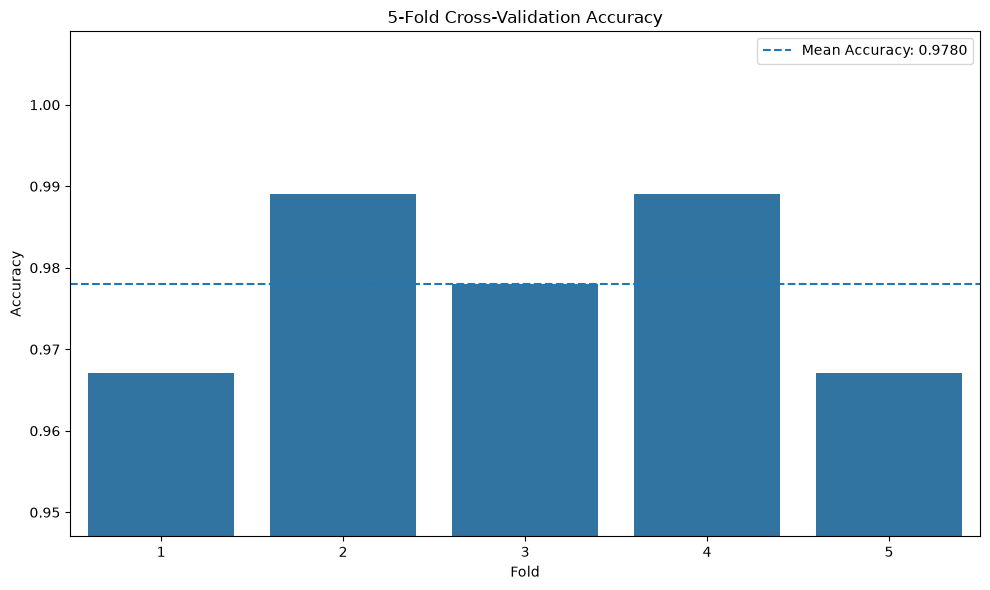

In [11]:
fold_accuracies = cv_results["test_accuracy"]

plt.figure(figsize=(10, 6))

sns.barplot(
    x=np.arange(1, 6),
    y=fold_accuracies
)

plt.axhline(
    np.mean(fold_accuracies),
    linestyle="--",
    label=f"Mean Accuracy: {np.mean(fold_accuracies):.4f}"
)

plt.title("5-Fold Cross-Validation Accuracy")
plt.xlabel("Fold")
plt.ylabel("Accuracy")

plt.ylim(
    min(fold_accuracies) - 0.02,
    max(fold_accuracies) + 0.02
)

plt.legend()

plt.tight_layout()
plt.show()

In [12]:
train_accuracy = cv_results["train_accuracy"]
validation_accuracy = cv_results["test_accuracy"]

comparison_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Training Accuracy": train_accuracy,
    "Validation Accuracy": validation_accuracy
})

comparison_df

,Fold,Training Accuracy,Validation Accuracy
0,1,0.989011,0.967033
1,2,0.989011,0.989011
2,3,0.989011,0.978022
3,4,0.989011,0.989011
4,5,0.989011,0.967033


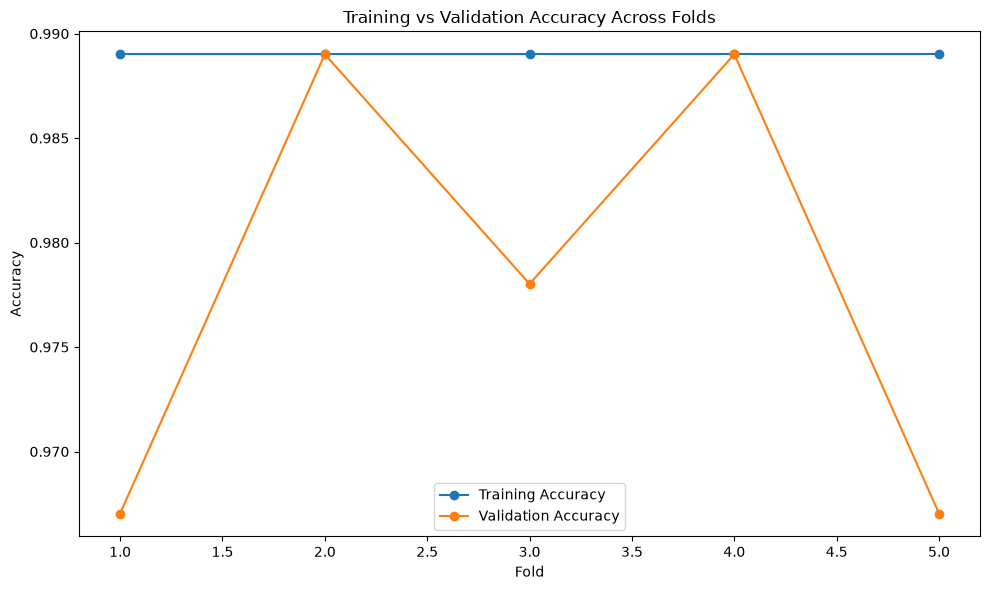

In [13]:
comparison_df.plot(
    x="Fold",
    y=["Training Accuracy", "Validation Accuracy"],
    kind="line",
    marker="o",
    figsize=(10, 6)
)

plt.title("Training vs Validation Accuracy Across Folds")
plt.xlabel("Fold")
plt.ylabel("Accuracy")

plt.tight_layout()
plt.show()